<a href="https://colab.research.google.com/github/lopezreyesleonardoa-sketch/Equipo-P-IA/blob/main/PIA_PPIA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Producto Integrador de Aprendizaje

Equipo:

Cristofer Jair Zuñiga Escobar 2189229

Leonardo Alfredo López Reyes 2181755

Diego Otoniel Cantu Cantu 2208782

Angel Gabriel Alonso Navarro 2116170

Alexis Eduardo Puente Mendoza 2188873

In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report

# 1. Carga del Conjunto de Datos Público

Para el desarrollo de este proyecto se imporatrá el dataset "Breast Cancer Wisconsin (Diagnostic)" utilizando la libreria "Pandas" y empezar con la visualización y análisis de datos.

In [20]:
# URL pública del dataset Breast Cancer Wisconsin (Diagnostic)
url = "https://raw.githubusercontent.com/scikit-learn/scikit-learn/main/sklearn/datasets/data/breast_cancer/breast_cancer.csv"
# O bien, se puede cargar directamente desde scikit-learn o un repositorio espejo verificado.
# Para fines prácticos de lectura directa con Pandas:
df = pd.read_csv("https://archive.ics.uci.edu/ml/machine-learning-databases/breast-cancer-wisconsin/wdbc.data", header=None)

# Asignación de nombres básicos a las columnas principales (ID, Diagnóstico y 30 características)
# Columna 0: ID, Columna 1: Diagnosis (M/B), Columnas 2-31: Características de los núcleos celulares.
print("Primeras filas del dataset original:")
print(df.head())

Primeras filas del dataset original:
         0  1      2      3       4       5        6        7       8   \
0    842302  M  17.99  10.38  122.80  1001.0  0.11840  0.27760  0.3001   
1    842517  M  20.57  17.77  132.90  1326.0  0.08474  0.07864  0.0869   
2  84300903  M  19.69  21.25  130.00  1203.0  0.10960  0.15990  0.1974   
3  84348301  M  11.42  20.38   77.58   386.1  0.14250  0.28390  0.2414   
4  84358402  M  20.29  14.34  135.10  1297.0  0.10030  0.13280  0.1980   

        9   ...     22     23      24      25      26      27      28      29  \
0  0.14710  ...  25.38  17.33  184.60  2019.0  0.1622  0.6656  0.7119  0.2654   
1  0.07017  ...  24.99  23.41  158.80  1956.0  0.1238  0.1866  0.2416  0.1860   
2  0.12790  ...  23.57  25.53  152.50  1709.0  0.1444  0.4245  0.4504  0.2430   
3  0.10520  ...  14.91  26.50   98.87   567.7  0.2098  0.8663  0.6869  0.2575   
4  0.10430  ...  22.54  16.67  152.20  1575.0  0.1374  0.2050  0.4000  0.1625   

       30       31  
0  0.4601 

# 2. Análisis Exploratorio y Visualización

Con la librería "Pandas" se obtendrá un resumen estadístico completo (conteo, media, desviación estándar, mínimos, cuartiles y máximos) de las principales variables de forma del dataset importado anteriormente con la misma librería, revisar los tipos de datos y detectar valores nulos, así como posibles anomalías estructurales.

In [21]:
#información
print("Resumen de la información del dataset:")
print(df.info())

#Conteo de las propiedades
print("Conteo de propiedades del dataset:")
print(df.count())

#Tamaño
print("Tamaño del dataset:")
print(df.shape)

#Media
print("Media del dataset:")
print(df.mean(numeric_only=True))

#Desviación estándar
print("Desviación estándar del dataset:")
print(df.std(numeric_only=True))

#Mínimos
print("Mínimos del dataset:")
print(df.min())

#Cuartiles
print("Cuartiles del dataset:")
print(df.quantile([0.25, 0.5, 0.75], numeric_only=True))

#Máximos
print("Máximos del dataset:")
print(df.max())

#Valores nulos
print("Valores nulos del dataset:")
print(df.isnull().sum())

Resumen de la información del dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 32 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   0       569 non-null    int64  
 1   1       569 non-null    object 
 2   2       569 non-null    float64
 3   3       569 non-null    float64
 4   4       569 non-null    float64
 5   5       569 non-null    float64
 6   6       569 non-null    float64
 7   7       569 non-null    float64
 8   8       569 non-null    float64
 9   9       569 non-null    float64
 10  10      569 non-null    float64
 11  11      569 non-null    float64
 12  12      569 non-null    float64
 13  13      569 non-null    float64
 14  14      569 non-null    float64
 15  15      569 non-null    float64
 16  16      569 non-null    float64
 17  17      569 non-null    float64
 18  18      569 non-null    float64
 19  19      569 non-null    float64
 20  20      569 non-null    float64
 21  

Con la librería matplotlib se generará un diagrama de dsipersión (scatter plot) que relacione la media del radio de los núcleos (mean radius) en el eje "X" con la media de la textura (mean texture) en el eje "Y", diferenciando con colores y leyendas a los tumores benignos y malignos. Además el gráfico se incorporarán etiquetas en los ejes, título y cuadrícula.

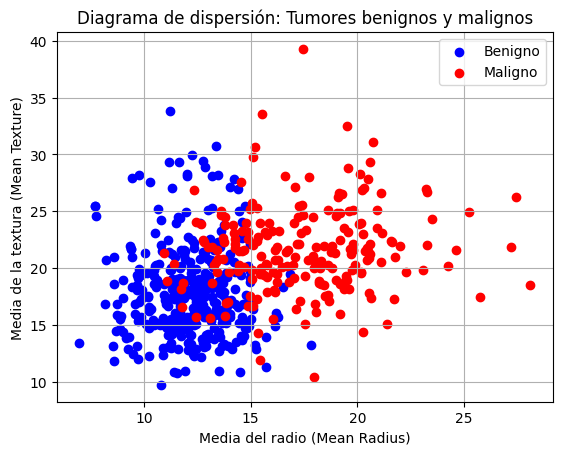

In [22]:
#Cálculo de medias que serán sometidas al diagrama de dispersión

mean_radius_benign = df[df[1] == 'B'][2]
mean_radius_malignant = df[df[1] == 'M'][2]
mean_texture_benign = df[df[1] == 'B'][3]
mean_texture_malignant = df[df[1] == 'M'][3]

#Diagrama Scatter plot
x_benign = mean_radius_benign
y_benign = mean_texture_benign
x_malignant = mean_radius_malignant
y_malignant = mean_texture_malignant

plt.scatter(mean_radius_benign, mean_texture_benign,
            color='blue', label='Benigno')
plt.scatter(mean_radius_malignant, mean_texture_malignant,
            color='red', label='Maligno')
plt.xlabel('Media del radio (Mean Radius)')
plt.ylabel('Media de la textura (Mean Texture)')
plt.title('Diagrama de dispersión: Tumores benignos y malignos')
plt.legend()
plt.grid(True)
plt.show()

#3. Limpieza y Preprocesamiento de Datos


Mediante la librería "Pandas" se revisará si existen valores nulos (valores faltantes o celdas vacías) en el DataFrame, así como la implementación de una estrategia de limpieza por definir. Se decidirá entre imputación con mediana o eliminación si el porcentaje es mínimo sobre cual es la más adecuada.

In [23]:
#Valores nulos
print("Valores nulos que existen:")
print(df.isnull().sum())
print((df.astype(str).apply(lambda x: x.str.strip() == '')).sum())
print("Porcentaje de valores nulos:")
porcentaje_nulos = (df.isnull().sum() / len(df)) * 100
print(porcentaje_nulos)
df = df.dropna()

Valores nulos que existen:
0     0
1     0
2     0
3     0
4     0
5     0
6     0
7     0
8     0
9     0
10    0
11    0
12    0
13    0
14    0
15    0
16    0
17    0
18    0
19    0
20    0
21    0
22    0
23    0
24    0
25    0
26    0
27    0
28    0
29    0
30    0
31    0
dtype: int64
0     0
1     0
2     0
3     0
4     0
5     0
6     0
7     0
8     0
9     0
10    0
11    0
12    0
13    0
14    0
15    0
16    0
17    0
18    0
19    0
20    0
21    0
22    0
23    0
24    0
25    0
26    0
27    0
28    0
29    0
30    0
31    0
dtype: int64
Porcentaje de valores nulos:
0     0.0
1     0.0
2     0.0
3     0.0
4     0.0
5     0.0
6     0.0
7     0.0
8     0.0
9     0.0
10    0.0
11    0.0
12    0.0
13    0.0
14    0.0
15    0.0
16    0.0
17    0.0
18    0.0
19    0.0
20    0.0
21    0.0
22    0.0
23    0.0
24    0.0
25    0.0
26    0.0
27    0.0
28    0.0
29    0.0
30    0.0
31    0.0
dtype: float64


In [24]:
print("como no hay valores nulos, no se aplica ningún método de eliminación")

como no hay valores nulos, no se aplica ningún método de eliminación


Se utilizará la librería NumPy para calcular el Rango Intercuartílico (IQR) de la variable mean area, mediante el primer y tercer cuartil. Posteriormente, se establecieron los límites inferior y superior utilizando 1.5 veces el IQR para identificar los valores atípicos.
Se filtrará el DataFrame para conservar únicamente los registros que se encuentran dentro de los límites establecidos, generando un nuevo DataFrame sin los valores atípicos identificados.

In [25]:

# Preparación de datos
# Columna 0: ID
# Columna 1: Diagnóstico (M/B)
# Columnas 2 a 31: Características

X = df.drop(columns=[0, 1]).copy()
y = df[1].map({'B': 0, 'M': 1})

# División de entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

# Cálculo del IQR para Mean Area (columna 5)
Q1 = np.percentile(X_train[5], 25)
Q3 = np.percentile(X_train[5], 75)

IQR = Q3 - Q1

limite_inferior = Q1 - (1.5 * IQR)
limite_superior = Q3 + (1.5 * IQR)

# Eliminar outliers únicamente del entrenamiento
filtro = (
    (X_train[5] >= limite_inferior) &
    (X_train[5] <= limite_superior)
)

registros_originales = len(X_train)

X_train = X_train.loc[filtro].copy()
y_train = y_train.loc[filtro].copy()

print("Primer cuartil (Q1):", Q1)
print("Tercer cuartil (Q3):", Q3)
print("Rango intercuartílico (IQR):", IQR)
print("Límite inferior:", limite_inferior)
print("Límite superior:", limite_superior)

print("\nRegistros originales de entrenamiento:", registros_originales)
print("Registros después de eliminar outliers:", len(X_train))
print("Registros eliminados:", registros_originales - len(X_train))
print("Registros de prueba:", len(X_test))


Primer cuartil (Q1): 420.35
Tercer cuartil (Q3): 796.65
Rango intercuartílico (IQR): 376.29999999999995
Límite inferior: -144.0999999999999
Límite superior: 1361.1

Registros originales de entrenamiento: 426
Registros después de eliminar outliers: 407
Registros eliminados: 19
Registros de prueba: 143


# 4 Entrenamiento y evaluacion del Arbol de Decision

Preparacion de datos: Separa el DataFrame limpio en dos componentes: la matriz de caracteristica independientes (x, excluyendo la coolumna de ID y la etiqueta de diagnóstico) y el vector de etiquetas objetivo (y, convirtiendo los valores categóricos 'M' y 'B' a valores numéricos binarios, por ejemplo, 1 para Maligno y 0 para Benigno).

2.Partición del conjunto: Divide los datos en conjuntos de entrenamiento y prueba utilizando la función de Scikit-Learn, asignando un 25% de los datos para la prueba y fijando una semilla de aleatoriedad (random_state=42) para garantizar la reproducibilidad.

3. Modelado y Métricas: Inicializa un clasificador de árbol de decisión con Scikit-Learn (`DecisionTreeClasifier`), entrénalo con el conjunto de entrenamiento y genera predicciones sobre el conjunto de prueba. Evalúa el desempeño del modelo calculando la exactitud (*Accuracy*) e imprimiendo el reporte de clasificación detallado (`classification_report`).

In [26]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report
import matplotlib.pyplot as plt

#Inicializar y entrenar el modelo
modelo_dt = DecisionTreeClassifier(random_state=42)
modelo_dt.fit(X_train, y_train)

# Generar predicciones sobre el cojunto de prueba
y_pred = modelo_dt.predict(X_test)

# Calcular exactitud y reporte de clasificacion
accuracy = accuracy_score(y_test, y_pred)
print(f"Exactitud (Accuracy): {accuracy:.4f} ({accuracy * 100:.2f}%)\n")
print("Reporte de Clasificacion:")
print(classification_report(y_test, y_pred, target_names=['Benigno (0)', 'Maligno (1)']))


Exactitud (Accuracy): 0.9580 (95.80%)

Reporte de Clasificacion:
              precision    recall  f1-score   support

 Benigno (0)       0.95      0.99      0.97        90
 Maligno (1)       0.98      0.91      0.94        53

    accuracy                           0.96       143
   macro avg       0.96      0.95      0.95       143
weighted avg       0.96      0.96      0.96       143



4. Visualización de la Estructura: Utiliza la función de ploteo de árboles de decisión de Scikit-Learn (`plot_tree`) en combinación con Matplotlib para graficar la estructura jerárquica del modelo entrenado, limitando la profundidad para una mejor legibilidad y especificando los nombres de las características y clases correspondientes.

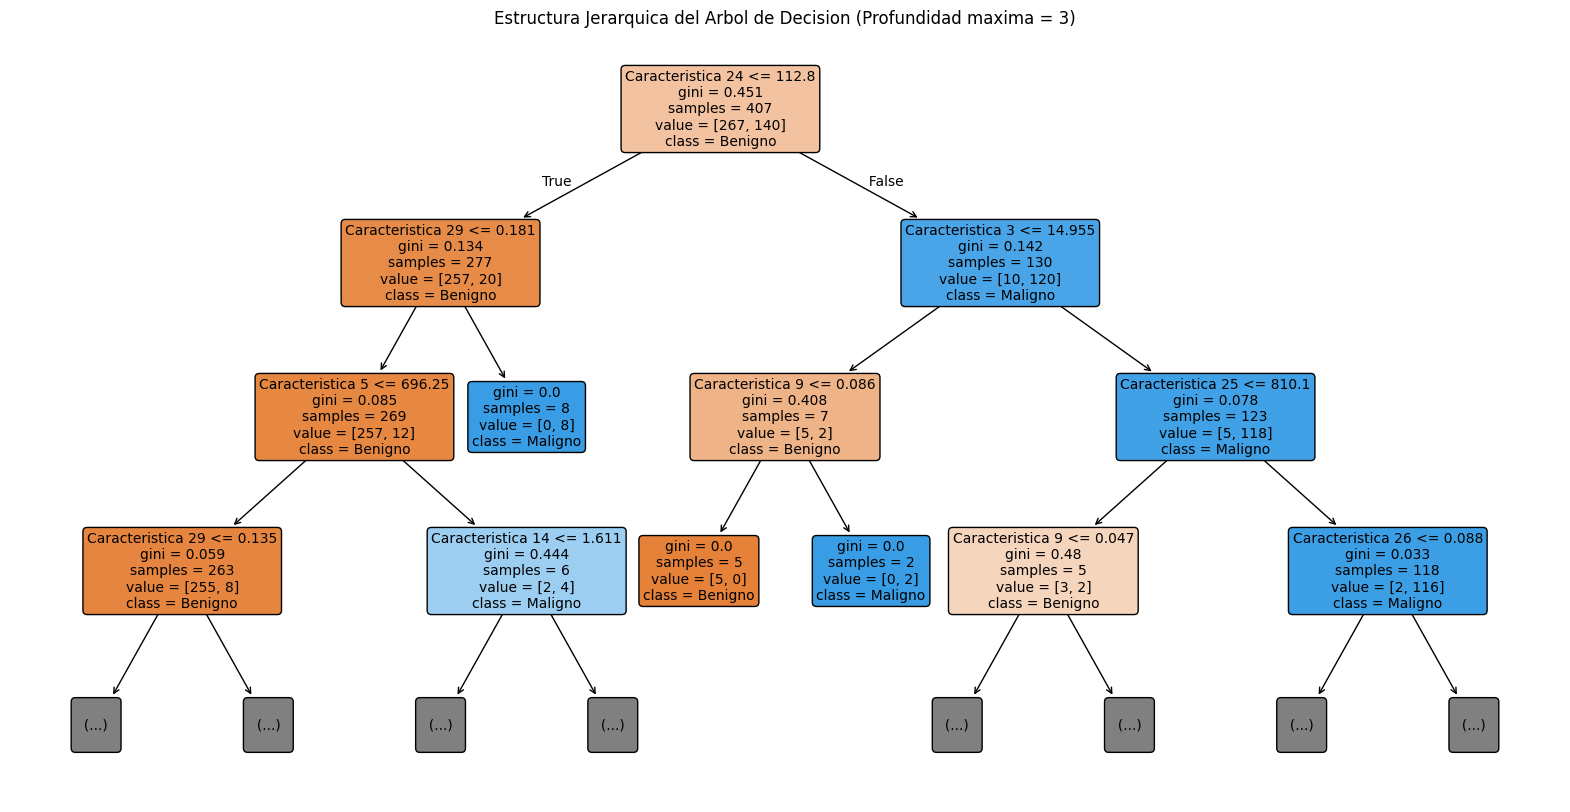

In [27]:

# Graficar la estructura del arbol de decision
plt.figure(figsize=(20, 10))

plot_tree(
    modelo_dt,
    feature_names=[f"Caracteristica {col}" for col in X.columns],
    class_names=['Benigno', 'Maligno'],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=10
)

plt.title("Estructura Jerarquica del Arbol de Decision (Profundidad maxima = 3)")
plt.show()
